# 03.3 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/03-decision-tree-classifier/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


## Exercise 1

- (10, 0): $p = 0$, $G = 1 - 0 - 1 = 0$
- (5, 5): $p = 0.5$, $G = 1 - 0.25 - 0.25 = 0.5$
- (7, 3): $p = 0.3$, $G = 1 - 0.09 - 0.49 = 0.42$
- (3, 7): $p = 0.7$, $G = 1 - 0.49 - 0.09 = 0.42$

The last two are equal: Gini does not care *which* class dominates, only how mixed the group is.

In [2]:
def gini(labels):
    """Gini impurity of a group of 0/1 labels."""
    p = np.mean(labels)
    return 1 - p**2 - (1 - p)**2

def split_impurity(df, feature, threshold, target="churned"):
    """Weighted Gini after splitting df on feature <= threshold."""
    left, right = df[df[feature] <= threshold][target], df[df[feature] > threshold][target]
    n = len(df)
    return len(left) / n * gini(left) + len(right) / n * gini(right)

for stayed, churned in [(10, 0), (5, 5), (7, 3), (3, 7)]:
    print((stayed, churned), round(gini([0] * stayed + [1] * churned), 3))

(10, 0) 0.0
(5, 5) 0.5
(7, 3) 0.42
(3, 7) 0.42


## Exercise 2

`items_last_month <= 4.5`: left = customers with items ≤ 4 (C001, C007, C009, C010, C018: 5 rows, all churned, $G = 0$); right = 15 rows, 4 churned, $p = 0.267$, $G = 1 - 0.071 - 0.538 = 0.391$. Weighted $= \frac{5}{20}(0) + \frac{15}{20}(0.391) = 0.293$. Worse than 0.25.

In [3]:
print(round(split_impurity(cust20, "items_last_month", 4.5), 3))

0.293


## Exercise 3

In [4]:
from sklearn.tree import DecisionTreeClassifier, export_text
p = 0.45
entropy_root = -p * np.log2(p) - (1 - p) * np.log2(1 - p)
print(f"root entropy: {entropy_root:.3f} bits")
tree_e = DecisionTreeClassifier(max_depth=2, criterion="entropy", random_state=0).fit(X20, y20)
print(export_text(tree_e, feature_names=list(X20.columns)))

root entropy: 0.993 bits
|--- visits_last_month <= 9.00
|   |--- visits_last_month <= 5.00
|   |   |--- class: 1
|   |--- visits_last_month >  5.00
|   |   |--- class: 1
|--- visits_last_month >  9.00
|   |--- days_since_last <= 31.50
|   |   |--- class: 0
|   |--- days_since_last >  31.50
|   |   |--- class: 0



Entropy ranks splits almost identically to Gini; on this data the tree is the same. Gini is the default because it is slightly cheaper to compute (no logarithm).

## Exercise 4

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


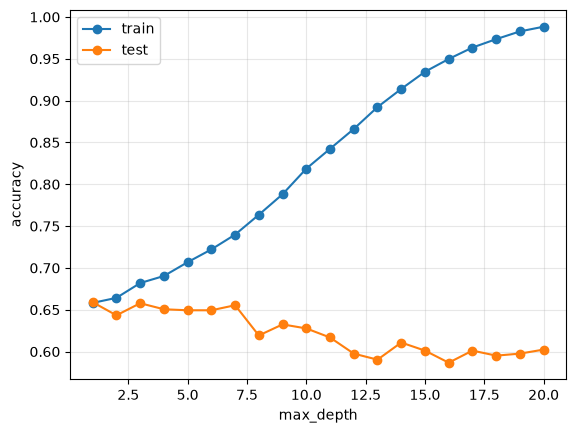

best test accuracy 65.9% at depth 1
min_samples_leaf=50, unlimited depth: train 70.7%, test 65.8%, depth reached 9


In [6]:
depths = range(1, 21)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train)); test_acc.append(t.score(X_test, y_test))
plt.plot(depths, train_acc, marker="o", label="train"); plt.plot(depths, test_acc, marker="o", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"best test accuracy {max(test_acc):.1%} at depth {list(depths)[int(np.argmax(test_acc))]}")

leafy = DecisionTreeClassifier(min_samples_leaf=50, random_state=0).fit(X_train, y_train)
print(f"min_samples_leaf=50, unlimited depth: train {leafy.score(X_train, y_train):.1%}, "
      f"test {leafy.score(X_test, y_test):.1%}, depth reached {leafy.get_depth()}")

Train accuracy climbs to 100%; test accuracy peaks early and then decays. `min_samples_leaf=50` is another way to stop the tree memorising: no leaf may describe fewer than 50 customers, so no rule can be about a handful of individuals.